In [11]:
# Dataset
import numpy as np
import matplotlib.pyplot as plt
from nnfs.datasets import spiral_data

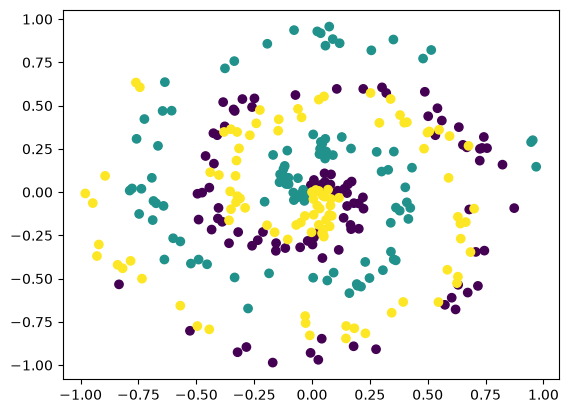

In [12]:
x, y = spiral_data(samples=100, classes=3)
plt.scatter(x[:,0], x[:,1], c=y)
plt.show()

### Layer Class

In [13]:
class Layer:

    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * np.random.randn(n_inputs, n_neurons)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.dot(self.inputs, self.weights) + self.biases

    def backward(self, dvalues):
        # weights
        self.dweights = np.dot(self.inputs.T, dvalues)
        # inputs
        self.dinputs = np.dot(dvalues, self.weights.T)
        # biases
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)

### ReLU Activation 

In [14]:
class ReLUActivation:
    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.maximum(self.inputs, 0)

    def backward(self, dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs<=0] = 0

### Softmax Activation

In [15]:
class SoftmaxActivation:
    def forward(self, inputs):
        exp_values = np.exp(inputs-np.max(inputs, axis=1, keepdims=True))
        self.outputs = exp_values / np.sum(exp_values, axis=1, keepdims=True)

### CCEL

In [16]:
class Loss:
    def calculate_loss(self, y_true, y_pred):
        return np.mean(self.forward(y_true, y_pred))

class CategoricalCrossEntropyLoss(Loss):

    def forward(self, y_true, y_pred):
        # y_true -> one hot encoded
        y_pred_clip = np.clip(y_pred, 1e-7, 1-1e-7)
        # prevent 0 and 1
        correct_confidences = np.sum(y_pred_clip * y_true, axis=1)
        neg_log_liklihoods = - np.log(correct_confidences)

        return neg_log_liklihoods

    def backward(self, dvalues, y_true):
        # y_true -> one hot encoded
        self.dinputs = - y_true/dvalues
        self.dinputs = self.dinputs/len(dvalues)

### Combination - Softmax & CCEL

In [17]:
class SoftMax_CCEL:
    def __init__(self):
        self.activation = SoftmaxActivation()
        self.ccel = CategoricalCrossEntropyLoss()

    def forward(self, inputs, y_true):
        self.activation.forward(inputs)
        self.outputs = self.activation.outputs

        return self.ccel.calculate_loss(y_true, self.outputs)

    def backward(self, dvalues, y_true):
        self.dinputs = dvalues - y_true
        # prediction - true value
        self.dinputs /= len(dvalues)

### Adam Optimizer

In [18]:
class AdamOptimizer:
    
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7, beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays, create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / (np.sqrt(weight_cache_corrected) + self.epsilon)
        layer.biases += -self.current_learning_rate * bias_momentums_corrected / (np.sqrt(bias_cache_corrected) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

### Model Training

In [19]:
y_encoded = np.eye(3)[y]

i/p layer -> layer 1 -> relu -> layer 2 -> softmax & loss -> optimizer

In [ ]:
l1 = Layer(2, 50)
af1 = ReLUActivation()

l2 = Layer(50, 3)
loss_af = SoftMax_CCEL()

opt = AdamOptimizer(learning_rate=0.02, decay=1e-5)

epochs = 100000

for _ in range(epochs):

    # forward pass
    l1.forward(x)
    af1.forward(l1.outputs)

    l2.forward(af1.outputs)
    loss = loss_af.forward(l2.outputs, y_encoded)

    prediction = np.argmax(loss_af.outputs, axis=1)
    y_encoded_idx = np.argmax(y_encoded, axis=1)
    
    acc = np.mean(prediction == y_encoded_idx)

    # backward pass
    loss_af.backward(loss_af.outputs, y_encoded)
    l2.backward(loss_af.dinputs)
    af1.backward(l2.dinputs)
    l1.backward(af1.dinputs)

    # optimizer
    opt.pre_update_params()
    opt.update_params(l1)
    opt.update_params(l2)
    opt.post_update_params()

    if not _%5000:
        print('Loss : ', loss,'\nAccuracy : ', acc,'\nIt : ',_,'\n---------')

Loss :  1.0986069521188926 
Accuracy :  0.35 
It :  0 
---------
Loss :  0.24402504954923315 
Accuracy :  0.89 
It :  5000 
---------
Loss :  0.20559218407441654 
Accuracy :  0.9033333333333333 
It :  10000 
---------
Loss :  0.19840835672612517 
Accuracy :  0.9066666666666666 
It :  15000 
---------
Loss :  0.19718513890979783 
Accuracy :  0.8966666666666666 
It :  20000 
---------
Loss :  0.17557510043460375 
Accuracy :  0.9133333333333333 
It :  25000 
---------
